# Proyecto Sprint 6

He recibido información para la tienda online de videojuegos Ice. Esta información incluye datos históricos de 2016 y a partir de los resultados del análisis se podrá implementar estrategias de mercadeo para 2017.

## 1. Apertura del archivo y revisión general del mismo.

In [1]:
#Importar librerias que se requieren para la ejecución del proyecto:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats as st

In [2]:
#Cargar archivo de análisis:
df_games = pd.read_csv('/datasets/games.csv')

In [3]:
#Revisar información general y presentar muestra de los datos:
print(df_games.info())
print()
print(df_games.sample(15))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB
None

                                             Name Platform  Year_of_Release  \
16045                    Turbo: Super Stunt Squad      3DS           2013.0   
6329                                   NBA Jam 99      N64           1998.0  

## Información preliminar:

a. Se tiene acceso a un listado de 16715 datos de juegos para el análisis. Esto representa una cantidad de datos suficiente para realizar un análisis adecuado.

b. Aparecen 16713 nombres de juegos. Se debe revisar que sucede con los nombres faltantes para determinar si se pueden eliminar estos registros.

c. Se tienen 16446 datos de año de lanzamiento. Dependiendo del análisis que se requiera hacer, se definirá que hacer con los datos faltantes. Preliminarmente optaría por despreciar que no se cuente con esta información.

d. Se tienen 16713 registros del género del juego. Revisaré si los datos faltantes estan en la misma línea que los nombres faltantes, lo que reforzaría la idea de eliminar estas entradas.

e. Se tienen datos de ventas en NorteAmérica, Europa, Japón y otras regiones para todas las entradas. Se revisará en las líneas faltantes si estas ventas son 0.0 o que valor y si son significativas para el análisis.

f. Se tienen 8137 datos de evaluaciones de la crítica. Esto requiere un estudio mas detallado antes de poder determinar como operar con los datos faltantes. Similar a lo que sucede con la evaluación de usuarios, que solo se dispone de 10014 registros.

g. Finalmente, para el Rating solo se dispone de 9949 datos. también se revisará la necesidad de manejar estos datos.

## 2. Preparación de los datos.

In [4]:
#Ajuste de nombre de columnas del dataframe a minúsculas y reemplazo de guiones por espacios:
df_games.columns = df_games.columns.str.lower().str.replace('_', ' ')

In [5]:
#Conversión de datos en tipos necesarios para análisis:

#1. 'year of release' de float a int:
df_games['year of release'] = pd.to_numeric(df_games['year of release'], errors='coerce')
df_games['year of release'] = df_games['year of release'].astype('Int64')  

#2. 'user score' de object a float64:
#Determinar datos de la columna 'user score'
print(df_games['user score'].value_counts())
#Cambio de tipo de datos
df_games['user score'] = pd.to_numeric(df_games['user score'], errors='coerce')


tbd    2424
7.8     324
8       290
8.2     282
8.3     254
       ... 
0.2       2
0.7       2
0.9       2
0         1
9.7       1
Name: user score, Length: 96, dtype: int64


Observaciones:

1. Se cambió la columna 'year of release' a tipo Int64. No tiene sentido manejar decimales en unos datos de tipo numérico entero.
2. Se cambia la columna 'user score' a tipo numérico. Inicialmente se revisa los valores posibles en esta columna, hallando 2424 datos como "tbd" (To Be Determined). Al realizar el cambio estos valores "tbd" se convierten en datos NaN. Este cambio se realiza para en un análisis posterior poder ejecutar operaciones aritméticas requeridas.

In [6]:
#Revisar registros con nombres faltantes
print("Registros sin nombre:")
print(df_games[df_games['name'].isnull()])

# Verificar si los datos faltantes están correlacionados
missing_data = df_games.isnull().sum()
print("Datos faltantes por columna:")
print(missing_data)

# Eliminar las filas donde 'name' es nulo
df_games = df_games.dropna(subset = ['name'])


Registros sin nombre:
      name platform  year of release genre  na sales  eu sales  jp sales  \
659    NaN      GEN             1993   NaN      1.78      0.53      0.00   
14244  NaN      GEN             1993   NaN      0.00      0.00      0.03   

       other sales  critic score  user score rating  
659           0.08           NaN         NaN    NaN  
14244         0.00           NaN         NaN    NaN  
Datos faltantes por columna:
name                  2
platform              0
year of release     269
genre                 2
na sales              0
eu sales              0
jp sales              0
other sales           0
critic score       8578
user score         9125
rating             6766
dtype: int64


Observaciones:

1. Al revisar los valores faltantes en la columna 'name', se encuentra que estos valores son de un par de juegos para la consola "GEN" (Genesis), y coincide en tener valores faltantes de calificación de usuarios, crítica y rating. aunque uno de estos juegos tiene ventas en NorteAmérica, Europa y Japón, teniendo en cuenta el número alto de registros total mayor a 16000 datos nos da herramientas suficientes para eliminarlo del DataFrame sin tener una mayor afectación.

### Tratamiento valores ausentes

In [7]:
#Columna 'year of release':

print("Registros nulos en 'year of release':")
print(df_games[df_games['year of release'].isnull()])

# Extraer el año del nombre
year_from_name = df_games['name'].str.extract(r'\b((?:19|20)\d{2})\b')
games_with_year_in_name = df_games[df_games['year of release'].isnull() & 
                                   year_from_name[0].notna()]

# Convertir el año extraído a tipo Int64 para que coincida con la columna
year_from_name[0] = pd.to_numeric(year_from_name[0], errors='coerce').astype('Int64')

# Asignar los años extraídos donde 'year of release' es nulo
mask = df_games['year of release'].isnull() & year_from_name[0].notna()
df_games.loc[mask, 'year of release'] = year_from_name.loc[mask, 0]



Registros nulos en 'year of release':
                                    name platform  year of release  \
183                      Madden NFL 2004      PS2             <NA>   
377                     FIFA Soccer 2004      PS2             <NA>   
456           LEGO Batman: The Videogame      Wii             <NA>   
475           wwe Smackdown vs. Raw 2006      PS2             <NA>   
609                       Space Invaders     2600             <NA>   
...                                  ...      ...              ...   
16373  PDC World Championship Darts 2008      PSP             <NA>   
16405                      Freaky Flyers       GC             <NA>   
16448                          Inversion       PC             <NA>   
16458        Hakuouki: Shinsengumi Kitan      PS3             <NA>   
16522                       Virtua Quest       GC             <NA>   

              genre  na sales  eu sales  jp sales  other sales  critic score  \
183          Sports      4.26      0.26  

In [8]:
#Columna 'critic score':

print("Registros nulos en 'critic score':")
print(df_games[df_games['critic score'].isnull()])

# Verificar si hay calificaciones de crítica igual a 0
zero_scores = df_games[df_games['critic score'] == 0.0]
print(f"Juegos con calificación de crítica = 0: {len(zero_scores)}")
print(zero_scores[['name', 'critic score', 'platform', 'year of release']])

# También puedes ver el valor mínimo
print(f"\nCalificación mínima: {df_games['critic score'].min()}")



Registros nulos en 'critic score':
                                name platform  year of release         genre  \
1                  Super Mario Bros.      NES             1985      Platform   
4           Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                             Tetris       GB             1989        Puzzle   
9                          Duck Hunt      NES             1984       Shooter   
10                        Nintendogs       DS             2005    Simulation   
...                              ...      ...              ...           ...   
16710  Samurai Warriors: Sanada Maru      PS3             2016        Action   
16711               LMA Manager 2007     X360             2006        Sports   
16712        Haitaka no Psychedelica      PSV             2016     Adventure   
16713               Spirits & Spells      GBA             2003      Platform   
16714            Winning Post 8 2016      PSV             2016    Simulation   

    

In [9]:
#Columna 'user score'
print(df_games['user score'].value_counts())

print("Registros nulos en 'user score':")
print(df_games[df_games['user score'].isnull()])

# Verificar si hay calificaciones de crítica igual a 0
zero_user_scores = df_games[df_games['user score'] == 0.0]
print(f"Juegos con calificación de usuarios = 0: {len(zero_user_scores)}")
print(zero_user_scores[['name', 'critic score', 'platform', 'year of release']])

# También puedes ver el valor mínimo
print(f"\nCalificación mínima: {df_games['user score'].min()}")

7.8    324
8.0    290
8.2    282
8.3    254
8.5    253
      ... 
0.9      2
1.9      2
1.3      2
9.7      1
0.0      1
Name: user score, Length: 95, dtype: int64
Registros nulos en 'user score':
                                name platform  year of release         genre  \
1                  Super Mario Bros.      NES             1985      Platform   
4           Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                             Tetris       GB             1989        Puzzle   
9                          Duck Hunt      NES             1984       Shooter   
10                        Nintendogs       DS             2005    Simulation   
...                              ...      ...              ...           ...   
16710  Samurai Warriors: Sanada Maru      PS3             2016        Action   
16711               LMA Manager 2007     X360             2006        Sports   
16712        Haitaka no Psychedelica      PSV             2016     Adventure   
167

In [10]:
#Columna 'rating'
print(df_games['rating'].value_counts())

print("Registros nulos en 'rating score':")
print(df_games[df_games['rating'].isnull()])

#Cambio de valores NaN por 'No Rated'
df_games['rating'] = df_games['rating'].fillna('No rated')

print(df_games.info())

E       3990
T       2961
M       1563
E10+    1420
EC         8
RP         3
K-A        3
AO         1
Name: rating, dtype: int64
Registros nulos en 'rating score':
                                name platform  year of release         genre  \
1                  Super Mario Bros.      NES             1985      Platform   
4           Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                             Tetris       GB             1989        Puzzle   
9                          Duck Hunt      NES             1984       Shooter   
10                        Nintendogs       DS             2005    Simulation   
...                              ...      ...              ...           ...   
16710  Samurai Warriors: Sanada Maru      PS3             2016        Action   
16711               LMA Manager 2007     X360             2006        Sports   
16712        Haitaka no Psychedelica      PSV             2016     Adventure   
16713               Spirits & Spel

Observaciones:

Para el tratamiento de valores ausentes se ha realizado lo siguiente:

Columna 'year of release':
1. Se revisan los juegos donde en la columna 'year of release' aparece como NaN. Se identificaron 17 juegos que tienen el año en su columna. por lo cual se extrae el año para adicionarlo a la columna años.
2. Los datos restantes se dejarán sin año especificado para poder continuar con análisis posteriores.

Columna 'critic score':

1. Se revisaron los juegos que no tienen calificación de la crítica. Coincidencialmente se encuentra que gran parte de estos juegos tampoco tienen calificación de usuarios ni Rating. Esto puede deberse a que o son juegos antiguos donde no se manejaba estas calificaciones, o juegos relativamente nuevos e incluso juegos de alcance limitado.
2. La calificación mínima de la critica fue de 13 puntos, no se encuentran calificaciones menores a este dato.
3. Se dejarán estos valores como NaN. Cambiar estos valores por 0 podría distorsionar análisis posteriores y sesgar estudios.

Columna 'user score':

1. Se revisaron los juegos que no tienen calificación de usuarios. Una revisión inicial corrobora lo que se había mencionado para la columna 'critic score', por lo que los comentarios realizados en dicha columna pueden extrapolarse en esta.
2. Se encuentra una calificación de usuarios 0 para un juego de Nintendo DS. Se revisará posteriormente el efecto de esta calificación en análisis mas profundos.
3. Al igual que en la columna 'critic score', se dejarán estos valores como NaN, ya que reemplazarlos por valores de 0 sesgará un análisis posterior, especialmente teniendo en cuenta que en esta columna si se tienen datos de calificaciones tan bajas.

Columna 'rating':

1. Para la columna 'rating se realiza la revisión de datos ausentes, encontrando 6764 datos ausentes.
2. Al ser una calificación categórica, no se tienen valores mínimos, que puedan afectar un análisis posterior. Por lo anterior, se realiza un cambio de tipo de datos de NaN por 'No Rated'


## 3. Análisis de datos.

Juegos lanzados por año:
year of release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     830
2003     779
2004     764
2005     941
2006    1008
2007    1198
2008    1429
2009    1427
2010    1255
2011    1137
2012     653
2013     545
2014     581
2015     606
2016     502
dtype: int64


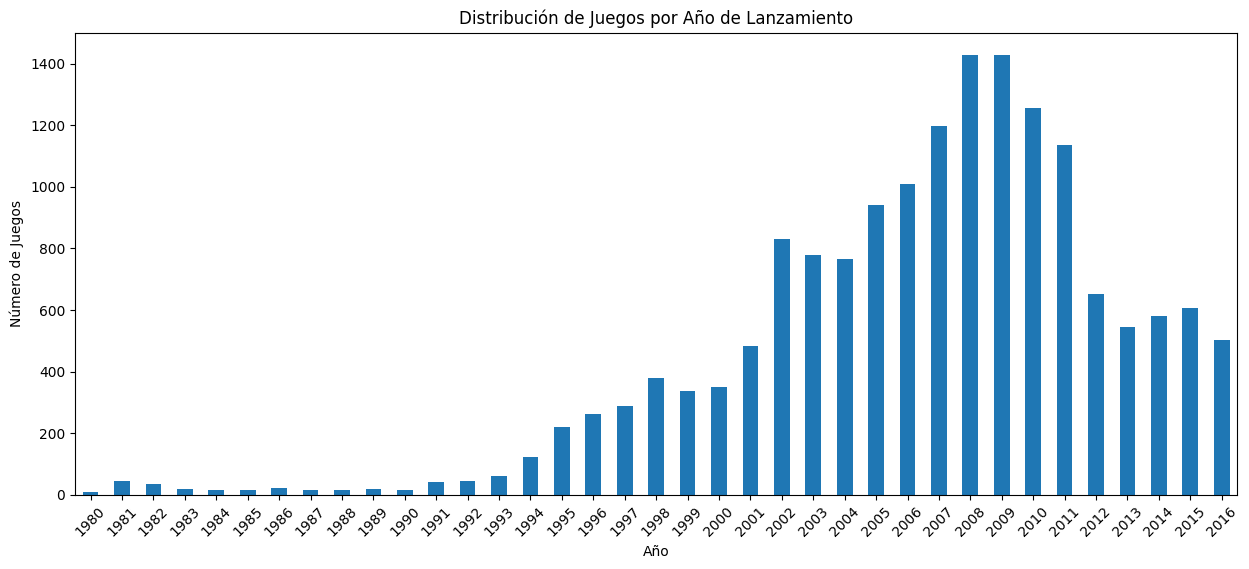

Años con datos: 1980 - 2016
Promedio de juegos por año: 444.9


In [11]:
#Juegos lanzados en diferentes año:
games_per_year = df_games.groupby('year of release').size()
print("Juegos lanzados por año:")
print(games_per_year)

# Visualizar la distribución
plt.figure(figsize = (15, 6))
games_per_year.plot(kind = 'bar')
plt.title('Distribución de Juegos por Año de Lanzamiento')
plt.xlabel('Año')
plt.ylabel('Número de Juegos')
plt.xticks(rotation=45)
plt.show()

# Estadísticas descriptivas
print(f"Años con datos: {games_per_year.index.min()} - {games_per_year.index.max()}")
print(f"Promedio de juegos por año: {games_per_year.mean():.1f}")


#### Observaciones:
1. La distribución de juegos por su año de lanzamiento sigue una tendencia de distribución normal con sesgo a la derecha.
2. Este comportamiento es algo normal debido al auge de las consolas como Play Station y Xbox que se lanzaron después del año 2000.
3. Se observa un pico de lanzamiento de juegos entre 2008 y 2009, y luego se empieza a notar una reducción paulatina en el lanzamiento de juegos. Esto puede estar asociado a la masificación de teléfonos mobiles como iphone y android y el crecimiento de redes sociales.

Primeras 5 filas de ventas totales:
                       name  na sales  eu sales  jp sales  other sales  \
0                Wii Sports     41.36     28.96      3.77         8.45   
1         Super Mario Bros.     29.08      3.58      6.81         0.77   
2            Mario Kart Wii     15.68     12.76      3.79         3.29   
3         Wii Sports Resort     15.61     10.93      3.28         2.95   
4  Pokemon Red/Pokemon Blue     11.27      8.89     10.22         1.00   

   total sales  
0        82.54  
1        40.24  
2        35.52  
3        32.77  
4        31.38  

Ventas totales - Estadísticas:
count    16713.000000
mean         0.533315
std          1.548282
min          0.000000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.540000
Name: total sales, dtype: float64

Numero total de ventas: 8913.289999999957
          total_sales  percentage  cumulative_percentage
platform                                                
PS2           1255

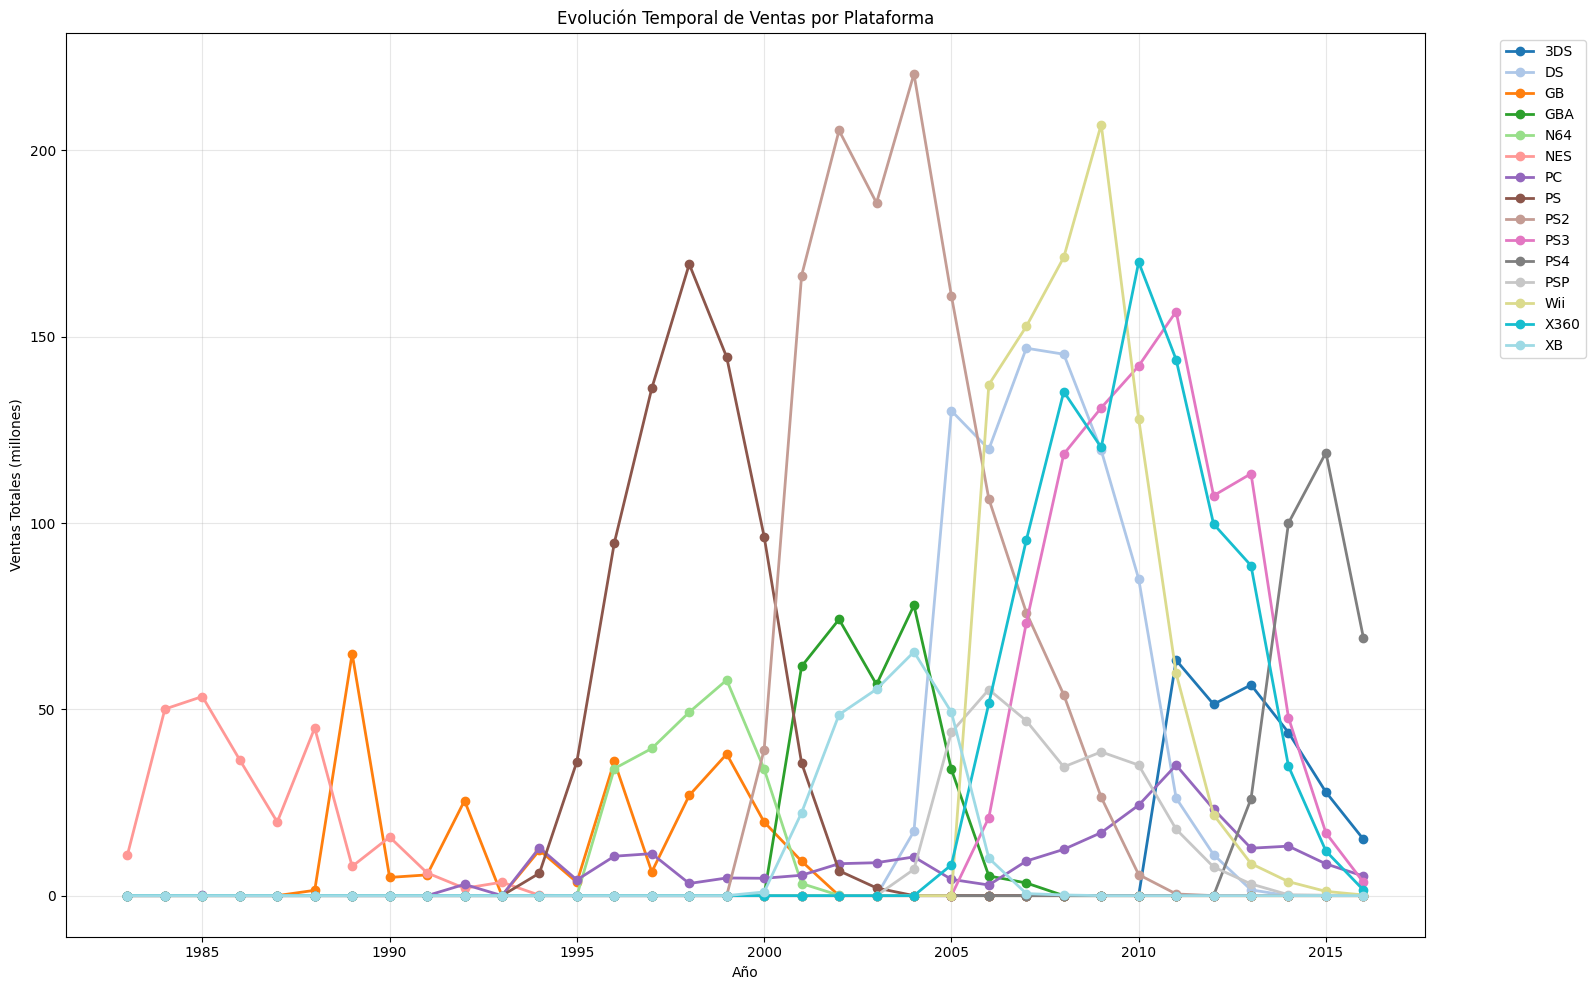

In [12]:
#Comparación de ventas por plataforma:
#Nueva columna d ventas totales
df_games['total sales'] = df_games['na sales'] + df_games['eu sales'] + df_games['jp sales'] + df_games['other sales']

# Verificar que se creó correctamente
print("Primeras 5 filas de ventas totales:")
print(df_games[['name', 'na sales', 'eu sales', 'jp sales', 'other sales', 'total sales']].head())

# Verificar estadísticas básicas
print(f"\nVentas totales - Estadísticas:")
print(df_games['total sales'].describe())
print()

#Discriminar por plataformas con mayores ventas:
games_platform = df_games.groupby('platform')['total sales'].sum().sort_values(ascending = False)

# Calcular el total de ventas del mercado
total_sales = games_platform.sum()
print(f'Numero total de ventas: {total_sales}')

# Calcular porcentajes
games_platform_pct = (games_platform / total_sales) * 100

# Crear un DataFrame combinando las dos series
platform_analysis = pd.DataFrame({'total_sales': games_platform, 'percentage': games_platform_pct})

# Agregar la columna de porcentaje acumulado
platform_analysis['cumulative_percentage'] = platform_analysis['percentage'].cumsum()

print(platform_analysis)

# Obtener las primeras 15 plataformas
top_15_platforms = platform_analysis.head(15).index.tolist()
print(f"Las 15 plataformas principales son: {top_15_platforms}")

# Filtrar el DataFrame df_games para incluir solo las 15 plataformas principales
games_per_platform = df_games[df_games['platform'].isin(top_15_platforms)]
print(f"Registros originales: {len(df_games)}")
print(f"Registros filtrados: {len(games_per_platform)}")
print(games_per_platform.head(10))
print()

#Agrupación de juegos por plataforma y por año:
sales_per_platform = games_per_platform.groupby(['year of release', 'platform'])['total sales'].sum()

print("Primeras 10 entradas:")
print(sales_per_platform.head(20))

print(f"\nTotal de combinaciones plataforma-año: {len(sales_per_platform)}")
print()


# Crear tabla pivote para el gráfico de líneas
pivot_data = sales_per_platform.reset_index().pivot(index='year of release', columns='platform', values='total sales')

# Rellenar valores NaN con 0 (años donde una plataforma no tuvo ventas)
pivot_data = pivot_data.fillna(0)

print("Estructura de datos para visualización:")
print(pivot_data.head())

# Configurar una paleta de colores más amplia
plt.figure(figsize=(16, 10))

# Usar la paleta 'tab20' que tiene 20 colores distintos
colors = plt.cm.tab20(np.linspace(0, 1, len(pivot_data.columns)))

# Crear el gráfico de líneas
for i, platform in enumerate(pivot_data.columns):
    plt.plot(pivot_data.index, pivot_data[platform], 
             marker='o', linewidth=2, label=platform, color=colors[i])

plt.title('Evolución Temporal de Ventas por Plataforma') #, fontsize=16, fontweight='bold')
plt.xlabel('Año') #, fontsize=12)
plt.ylabel('Ventas Totales (millones)') #, fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



#### Observaciones:

1. Para enriquecer el análisis, primero se crea una columna donde se calculan las ventas totales de cada juego.
2. Luego se realiza un análisis para determinar las plataformas que generan mas ventas. se realiza una segregación de 15 plataformas que dominan el 90% de las ventas totales.
3. Una vez obtenidas estas plataformas, agrupamos los juegos por plataforma y por año para poder determinar las ventas totales obtenidas por juego y por año.
4. Con estos datos se realiza un gráfico de líneas donde se pueda divisar el comportamiento de ventas para cada plataforma en el tiempo y se pueda establecer su distribución.
5. Se puede observar que por lo general, las ventas de videojuegos por plataforma siguen una distribución normal.
6. En algunas plataformas como 'GB' (Posiblemente Gameboy), se observan muchos picos en el tiempo analizado. Esto puede deberse al lanzamiento de juegos específicos e icónicos para esta plataforma, o en algunos casos por mejoras realizadas en juegos y en la plataforma como tal.
7. Algunos juegos presentan dos picos de ventas que pueden deberse a lanzamiento de juegos específicos para la plataforma.
8. Plataformas como 'PC' presentan una vida útil larga pero se encuentran en declive a nivel de ventas, pero esto se ocasiona por el auge de juegos que se utilizan y comercializan en línea.
10. En promedio, una plataforma tiene una vida útil de 10 años.
11. Las plataformas se toman en general aproximadamente 5 años en crecer, obtienen su pico de ventas y toman otros 5 años de decadencia y desaparición. Posiblemente debido al lanzamiento de nuevas plataformas.

In [15]:
# Análisis de relevancia temporal
def platform_relevance_by_period(df):
    """
    Analiza qué plataformas estaban activas en diferentes períodos
    """
    periods = {
        'Último año (2016)': df[df['year of release'] >= 2016],
        'Últimos 5 años (2012-2016)': df[df['year of release'] >= 2012],
        'Últimos 10 años (2007-2016)': df[df['year of release'] >= 2007],
        'Todos los datos': df
    }
    
    for period_name, period_data in periods.items():
        active_platforms = period_data['platform'].nunique()
        total_sales = period_data['total sales'].sum()
        print(f"{period_name}:")
        print(f"  - Plataformas activas: {active_platforms}")
        print(f"  - Ventas totales: {total_sales:.2f}M")
        print(f"  - Juegos lanzados: {len(period_data)}")
        print()

relevance = platform_relevance_by_period(df_games)


Último año (2016):
  - Plataformas activas: 9
  - Ventas totales: 129.94M
  - Juegos lanzados: 502

Últimos 5 años (2012-2016):
  - Plataformas activas: 11
  - Ventas totales: 1446.88M
  - Juegos lanzados: 2887

Últimos 10 años (2007-2016):
  - Plataformas activas: 16
  - Ventas totales: 4480.54M
  - Juegos lanzados: 9333

Todos los datos:
  - Plataformas activas: 31
  - Ventas totales: 8913.29M
  - Juegos lanzados: 16713



#### Observaciones:
1. Se realiza un análisis de relevancia de la ventas de los juegos en los intervalos:
   - Último año.
   - Últimos 5 años.
   - Últimos 10 años.
   - Todo el rango de años.  
2. Este análisis de relevancia muestra que solo hay 10 plataformas de relevancia en el último año, y que entre los últimos 5 años y el último año solo 1 plataforma ha desaparecido.
3. Se tomará entonces un periodo de análisis de los últimos 5 años para el estudio. esto permitirá:
   - Abarcar plataformas que estan dentro del ciclo de vida de los juegos, ya sea porque estan en su auge o en su declive.
   - Incluir aspectos como reseñas de usuarios y críticos que están "frescas".
   - Incluir plataformas que estarán activas para 2017.

In [16]:
# Filtrar df_games para incluir solo los últimos 5 años (2012-2016)
df_games_filtered = df_games[df_games['year of release'] >= 2012].copy()

# Identificar las plataformas activas en este período
active_platforms = df_games_filtered['platform'].unique()
print(f"Plataformas activas 2012-2016: {len(active_platforms)}")
print(f"Plataformas: {sorted(active_platforms)}")

# Si quieres ser más específico y usar solo las 11 plataformas más relevantes:
platform_sales = df_games_filtered.groupby('platform')['total sales'].sum().sort_values(ascending=False)
top_platforms = platform_sales.head(11).index.tolist()

# Filtro final con las 11 plataformas más relevantes
df_games_final = df_games_filtered[df_games_filtered['platform'].isin(top_platforms)].copy()

print(f"\nDataset final:")
print(f"Registros: {len(df_games_final)}")
print(f"Plataformas: {len(df_games_final['platform'].unique())}")
print(f"Años: {df_games_final['year of release'].min()} - {df_games_final['year of release'].max()}")



Plataformas activas 2012-2016: 11
Plataformas: ['3DS', 'DS', 'PC', 'PS3', 'PS4', 'PSP', 'PSV', 'Wii', 'WiiU', 'X360', 'XOne']

Dataset final:
Registros: 2887
Plataformas: 11
Años: 2012 - 2016


#### Observaciones:
1. Se realiza un filtrado al dataframe original df_games para separar los juegos por año desde el 2012 en adelante.
2. Luego se agrupan por plataforma y por ventas totales.
3. Finalmente se realiza el filtrado de las 11 plataformas que han registrado ventas desde 2012 en adelante.


Top 11 plataformas por ventas (2012-2016):
 1. PS4: 314.14M
 2. PS3: 288.79M
 3. X360: 236.54M
 4. 3DS: 194.61M
 5. XOne: 159.32M
 6. WiiU: 82.19M
 7. PC: 63.00M
 8. PSV: 49.18M
 9. Wii: 35.37M
10. DS: 12.55M
11. PSP: 11.19M
Ventas por año y plataforma:
year of release  platform
2012             3DS          51.36
                 DS           11.01
                 PC           23.22
                 PS3         107.36
                 PSP           7.69
                 PSV          16.19
                 Wii          21.71
                 WiiU         17.56
                 X360         99.74
2013             3DS          56.57
Name: total sales, dtype: float64

Forma de los datos: (49,)
Datos preparados para visualización:
platform           3DS     DS     PC     PS3     PS4   PSP    PSV    Wii  \
year of release                                                            
2012             51.36  11.01  23.22  107.36    0.00  7.69  16.19  21.71   
2013             56.57   1.54  12

<Figure size 1500x800 with 0 Axes>

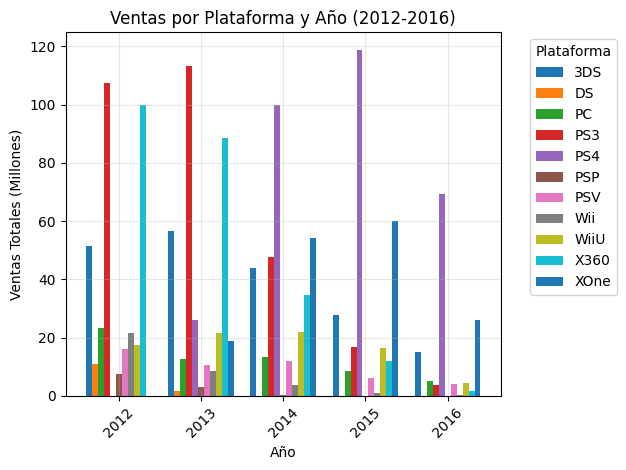

In [17]:
#Plataformas líderes en ventas:
print(f"\nTop 11 plataformas por ventas (2012-2016):")
for i, platform in enumerate(top_platforms, 1):
    sales = platform_sales[platform]
    print(f"{i:2d}. {platform}: {sales:.2f}M")

platform_year_sales = df_games_final.groupby(['year of release', 'platform'])['total sales'].sum()

print("Ventas por año y plataforma:")
print(platform_year_sales.head(10))
print(f"\nForma de los datos: {platform_year_sales.shape}")

# Convertir a tabla pivote
pivot_data2 = platform_year_sales.reset_index().pivot(index='year of release', columns='platform', values='total sales')
pivot_data2 = pivot_data2.fillna(0)
print("Datos preparados para visualización:")
print(pivot_data2)

# Configurar el gráfico
plt.figure(figsize=(15, 8))
pivot_data2.plot(kind='bar', width=0.8)
plt.title('Ventas por Plataforma y Año (2012-2016)')
plt.xlabel('Año')
plt.ylabel('Ventas Totales (Millones)')
plt.legend(title='Plataforma', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Observaciones:

1. Se realiza un análisis sobre las 11 plataformas que presentaron actividad en los últimos 5 años.
2. Se revisaron cuales son las que presentan un marcado liderazgo en las ventas globales de juegos. Se encuentra que las mejores plataformas de los últimos 5 años son PS4, PS3 y X360, las cuales manejan mas del 50% de las ventas totales del periodo estudiado.
3. Luego de ello, se realiza una nueva agrupación por año y por plataforma para las 11 plataformas analizadas para identificar patrones de crecimiento o declive.
4. Se onserva que en general, 206 no fue un buen año respecto a las ventas de videojuegos ya que todas las plataformas presentaron una reducción de ventas significativa. Hay que tener en cuenta que la distribución de juegos en línea marca una tendencia que se debe tener en cuenta para realizar cualquier tipo de campaña de mercadeo.
5. Se ha encontrado que las plataformas PS3 y X360, a pesar de liderar las ventas durante el periodo, se encuentran en franco declive, debido a la aparición de plataformas mejoradas como PS4 o XOne.
6. Plataformas desaparecidas durante el periodo: DS, PSP.
7. Plataformas en declive: PS3, Wii, X360
8. Plataformas con potencial de rentabilidad: 3DS, PC, PS4, PSV, WiiU, XOne.
9. Para las plataformas con potencial, realmente las plataformas PSV, PC y WiiU tienen mercados muy pequeños debido a:
    - Plataformas como PSV, WiiU y PC son para mercados reducidos.
    - Para PC, XOne y PS4 se ha venido viendo ampliación de juegos en línea. No obstante, son plataformas atractivas y que se deben explotar.

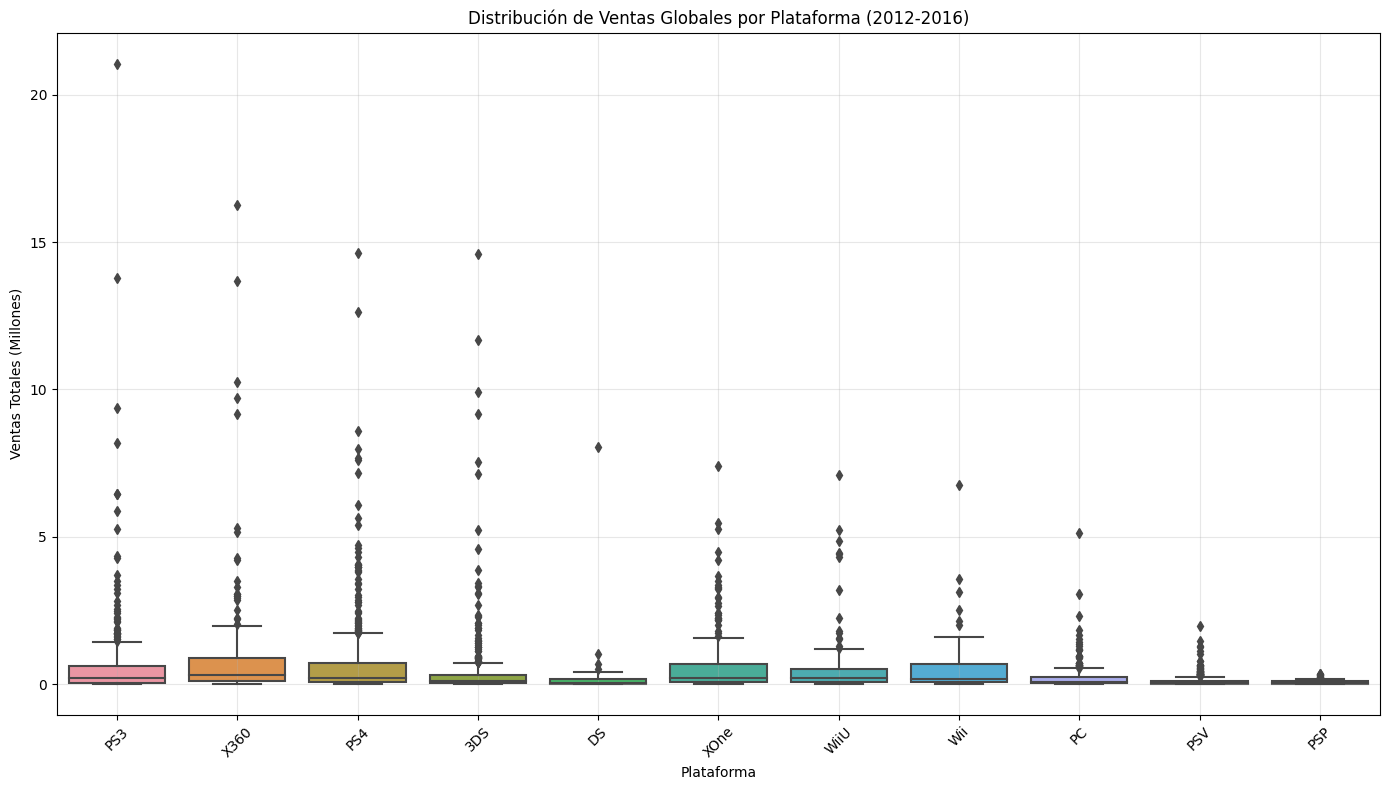

Estadísticas descriptivas por plataforma:
          count   mean    std   min    25%   50%    75%    max
platform                                                      
3DS       396.0  0.491  1.387  0.01  0.040  0.11  0.313  14.60
DS         31.0  0.405  1.439  0.01  0.020  0.05  0.185   8.06
PC        251.0  0.251  0.494  0.01  0.030  0.08  0.240   5.14
PS3       493.0  0.586  1.463  0.01  0.050  0.20  0.610  21.05
PS4       392.0  0.801  1.609  0.01  0.060  0.20  0.730  14.63
PSP       173.0  0.065  0.071  0.01  0.020  0.03  0.090   0.36
PSV       411.0  0.120  0.203  0.01  0.020  0.05  0.120   1.96
Wii        54.0  0.655  1.165  0.01  0.062  0.18  0.688   6.76
WiiU      147.0  0.559  1.059  0.01  0.080  0.22  0.525   7.09
X360      292.0  0.810  1.712  0.01  0.100  0.31  0.870  16.27
XOne      247.0  0.645  1.036  0.01  0.060  0.22  0.685   7.39

Ventas promedio por plataforma:
X360: 0.810M
PS4: 0.801M
Wii: 0.655M
XOne: 0.645M
PS3: 0.586M
WiiU: 0.559M
3DS: 0.491M
DS: 0.405M
PC: 0.25

In [18]:
# Crear el diagrama de caja para ventas globales por plataforma
plt.figure(figsize=(14, 8))
sns.boxplot(data=df_games_final, x='platform', y='total sales')
plt.title('Distribución de Ventas Globales por Plataforma (2012-2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas Totales (Millones)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Estadísticas descriptivas por plataforma
platform_stats = df_games_final.groupby('platform')['total sales'].describe()
print("Estadísticas descriptivas por plataforma:")
print(platform_stats.round(3))

# Ventas promedio por plataforma
avg_sales = df_games_final.groupby('platform')['total sales'].mean().sort_values(ascending=False)
print("\nVentas promedio por plataforma:")
for platform, avg in avg_sales.items():
    print(f"{platform}: {avg:.3f}M")

#### Observaciones:

1. Se realiza el diagrama de caja para las ventas de juegos por plataforma en el periodo de 2012-2016.
2. Se encuentra alta presencia de datos atípicos en varias plataformas como PS3, PS4, X360, 3DS y XOne. Esto posiblemente ocasionado por lanzamientos de juegos exclusivos para plataforma y que se convirtieron en juegos emblématicos para las mismas.
3. Se registran picos de ventas superiores a los 10 millones, sin embargo, las medias no superan el millon en ventas. Esto confirma la hipótesis anterior.
4. A excepción de plataformas como PSP, PSV y PC, se observa una amplia dispersión de los resultados de ventas. Esto puede ser debido al catálogo amplio de juegos que ofrecen, que abarcan gran parte del mercado.
5. Hay que acotar que la plataforma PC, a pesar de no tener un impacto superlativo en las ventas, es una plataforma constante en las mismas, lo que indica un alto grado de fidelización de sus usuarios y que puede aprovecharse en un plan para 2017.
6. Las plataformas X360 y PS3 presentan los mayores registros en ventas, pero se debe tener en cuenta que son plataformas en declive por la presencia de Plataformas mejoradas de las mismas casas que las produjeron.
7. Se confirma también que plataformas como PS4, XOne, 3DS y WiiU tienen gran posibilidad de dominar el mercado en años venideros.

Total de juegos para X360: 292
Juegos con critic score: 171
Juegos con user score: 235
Juegos con ambas puntuaciones: 171


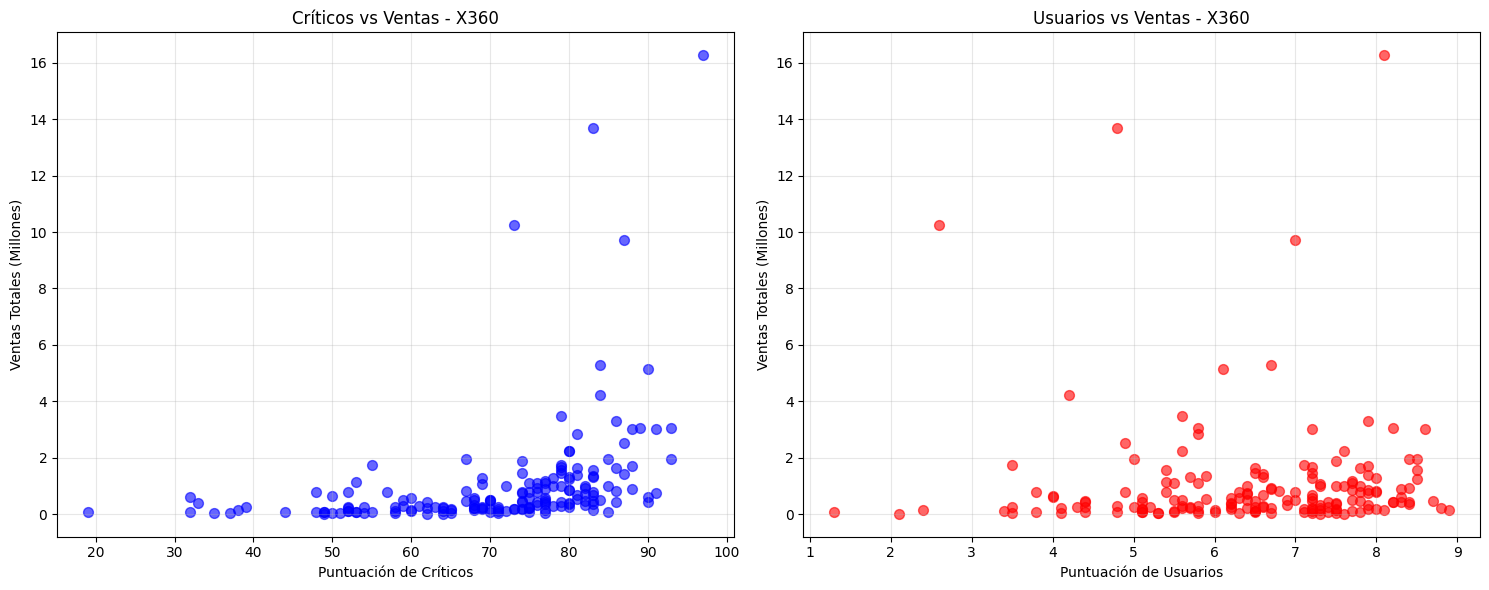

La correlación para 'Critic score' es: 0.361
La correlación para 'user score' es: -0.002


In [19]:
#Efecto reseñas de usuarios y críticos para plataforma PS3:

# Filtrar datos para la plataforma X360
x360_games = df_games_final[df_games_final['platform'] == 'X360'].copy()

# Verificar cuántos juegos tenemos
print(f"Total de juegos para X360: {len(x360_games)}")
print(f"Juegos con critic score: {x360_games['critic score'].notna().sum()}")
print(f"Juegos con user score: {x360_games['user score'].notna().sum()}")
print(f"Juegos con ambas puntuaciones: {(x360_games['critic score'].notna() & x360_games['user score'].notna()).sum()}")

# Crear subplots para ambas correlaciones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Filtrar datos con puntuaciones válidas
x360_with_scores = x360_games.dropna(subset=['critic score', 'user score'])

# Gráfico 1: Critic Score vs Ventas Totales
ax1.scatter(x360_with_scores['critic score'], x360_with_scores['total sales'], 
           alpha=0.6, color='blue', s=50)
ax1.set_xlabel('Puntuación de Críticos')
ax1.set_ylabel('Ventas Totales (Millones)')
ax1.set_title('Críticos vs Ventas - X360')
ax1.grid(True, alpha=0.3)

# Gráfico 2: User Score vs Ventas Totales
ax2.scatter(x360_with_scores['user score'], x360_with_scores['total sales'], 
           alpha=0.6, color='red', s=50)
ax2.set_xlabel('Puntuación de Usuarios')
ax2.set_ylabel('Ventas Totales (Millones)')
ax2.set_title('Usuarios vs Ventas - X360')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

from scipy.stats import pearsonr

# Calcular correlaciones
critic_corr, critic_p = pearsonr(x360_with_scores['critic score'], x360_with_scores['total sales'])
user_corr, user_p = pearsonr(x360_with_scores['user score'], x360_with_scores['total sales'])

print(f"La correlación para 'Critic score' es: {critic_corr:.3f}")
print(f"La correlación para 'user score' es: {user_corr:.3f}")

#### Observaciones:

1. Se realiza un análisis a una plataforma en particular. Se selecciona la plataforma X360 ya que tiene una buena cantidad de juegos (292), y presenta una cantidad de evaluaciones de criticos (171) y usuarios (292), las cuales superan el 50% del catalogo de juegos lanzados para esta plataforma.
2. Se realiza un análisis de dispersión de las ventas respecto a la calificación de usuarios y de critica. se encuentra que:
   - Se puede notar una lígera tendencia positiva de aumento de ventas respecto a buenas evaluaciones de la crítica. Se observa un par de datos atípicos que pueden deberse a una secuela de algún juego de saga que si bien no fue bien calificado por la crítica, por el efecto de versiones anteriores del juego pudo tener buen impacto en las ventas.
   - No se observa el mismo comportamiento en el efecto de la calificación de usuarios en las ventas. Se observa una pequeña tendencia positiva pero no es definitiva y se ven más datos donde una calificación no tan buena si presenta buenas ventas.
   - Lo que si se observa en general es que un juego mal calificado, ya sea por usuarios o por la crítica, no tiene buenas ventas.
3. Las correlaciones obtenidas para ambas evaluaciones son muy bajas, corroborando lo visto anteriormente.


Juegos que aparecen en múltiples plataformas: 596
Juegos con mayor presencia multiplataforma:
name
LEGO Marvel Super Heroes        9
FIFA 14                         9
The LEGO Movie Videogame        8
Angry Birds Star Wars           8
FIFA 15                         8
FIFA Soccer 13                  8
LEGO The Hobbit                 8
LEGO Jurassic World             8
Lego Batman 3: Beyond Gotham    8
Skylanders: Trap Team           7
Name: platform, dtype: int64

Top 5 juegos multiplataforma: name
LEGO Marvel Super Heroes    9
FIFA 14                     9
The LEGO Movie Videogame    8
Angry Birds Star Wars       8
FIFA 15                     8
Name: platform, dtype: int64

Datos preparados para visualización:
name      Angry Birds Star Wars  FIFA 14  FIFA 15  LEGO Marvel Super Heroes  \
platform                                                                      
3DS                        0.33     0.23     0.46                      0.89   
DS                         0.00     0.00  

<Figure size 1600x500 with 0 Axes>

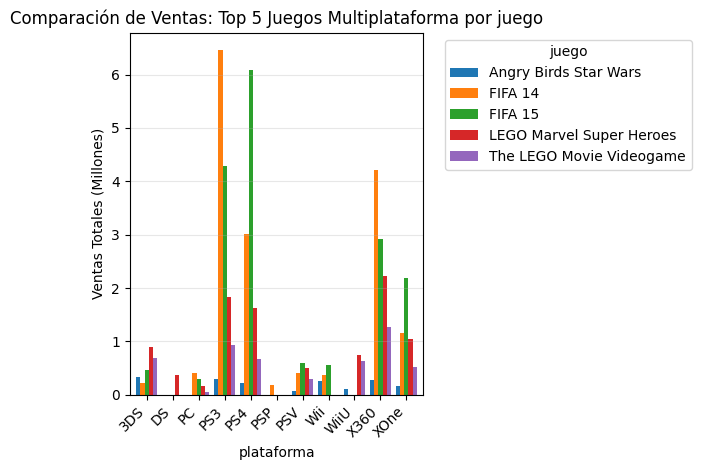

In [21]:
#Comparación de juegos en varias plataformas:

# Identificar juegos que aparecen en múltiples plataformas
games_multiplatform = df_games_final.groupby('name')['platform'].nunique()

# Filtrar solo juegos que aparecen en 2 o más plataformas
multiplatform_games = games_multiplatform[games_multiplatform >= 2]

print(f"Juegos que aparecen en múltiples plataformas: {len(multiplatform_games)}")
print(f"Juegos con mayor presencia multiplataforma:")
print(multiplatform_games.sort_values(ascending=False).head(10))
print()

# Obtener los 5 juegos con mayor presencia multiplataforma
top_5_games = multiplatform_games.sort_values(ascending=False).head(5)
print(f"Top 5 juegos multiplataforma: {top_5_games}")
print()

# Obtener los nombres de estos juegos y filtrar estos juegos
top_5_names = top_5_games.index.tolist()
top_5_data = df_games_final[df_games_final['name'].isin(top_5_names)]

# Crear tabla pivote: plataformas como filas, juegos como columnas, ventas como valores
pivot_sales3 = top_5_data.pivot_table(
    index='platform', 
    columns='name', 
    values='total sales', 
    fill_value=0)

print("Datos preparados para visualización:")
print(pivot_sales3)

# Crear el gráfico de barras agrupadas
plt.figure(figsize=(16, 5))
pivot_sales3.plot(kind='bar', width=0.8)

plt.title('Comparación de Ventas: Top 5 Juegos Multiplataforma por juego')
plt.xlabel('plataforma')
plt.ylabel('Ventas Totales (Millones)')
plt.legend(title='juego', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### Observaciones:

1. Se realiza un filtrado de las ventas de juegos en el periodo 2012-2016. Se encuentran 596 juegos que se enceuntran en varias plataformas.
2. De este listado de juegos, se observa que los juegos de fútbol de FIFA y la franquicia Lego son los de mayor cobertura en plataformas con mas de 8 plataformas disponibles.
3. Se realiza un filtrado para analizar las ventas en los 5 juegos que mas presencia tienen en plataformas.
4. Se encuentra que las ventas de los 5 principales juegos multiplataformas dominan en las plataformas PS3, PS4, X360 y XOne. El dominio en las demas plataformas es de menor alcance.

Análisis completo por género:
                 sum  mean  count  median
genre                                    
Action        441.47  0.43   1032    0.12
Shooter       304.73  1.30    235    0.44
Role-Playing  192.80  0.52    370    0.14
Sports        181.07  0.68    268    0.24
Misc           85.04  0.44    192    0.12
Platform       61.00  0.72     85    0.21
Racing         53.50  0.47    115    0.14
Fighting       44.49  0.41    109    0.13
Simulation     35.12  0.44     80    0.12
Adventure      29.43  0.10    302    0.03
Strategy       13.34  0.19     71    0.08
Puzzle          4.89  0.17     28    0.04

Rentabilidad por género (ventas totales / cantidad de juegos):
                 sum  count  rentabilidad
genre                                    
Shooter       304.73    235      1.296723
Platform       61.00     85      0.717647
Sports        181.07    268      0.675634
Role-Playing  192.80    370      0.521081
Racing         53.50    115      0.465217
Misc           85.04    

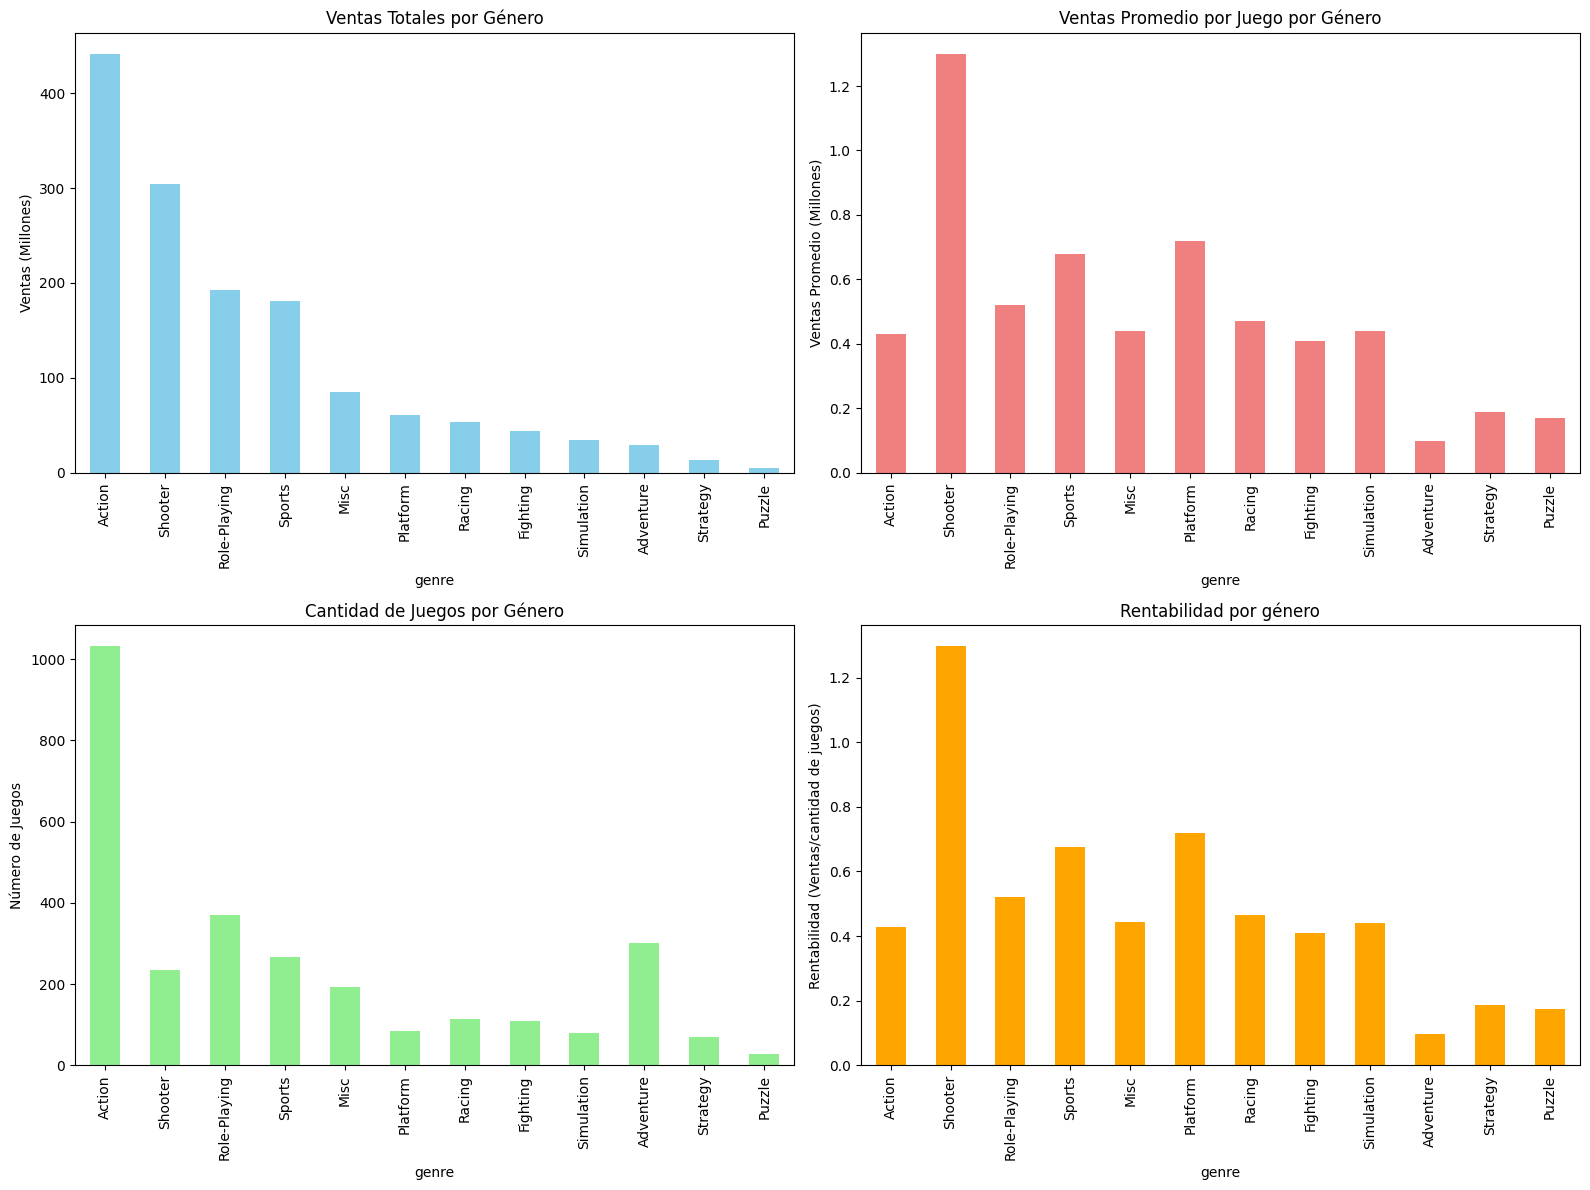

In [22]:
#Análisis por género:
genre_games = df_games_final.groupby('genre')['total sales'].sum()

# Análisis más completo por género
genre_analysis = df_games_final.groupby('genre')['total sales'].agg([
    'sum',      # Ventas totales
    'mean',     # Ventas promedio por juego
    'count',    # Cantidad de juegos
    'median'    # Mediana de ventas
]).round(2)

# Ordenar por ventas totales
genre_analysis = genre_analysis.sort_values('sum', ascending=False)
print("Análisis completo por género:")
print(genre_analysis)

# Crear categorías de rentabilidad
genre_analysis['rentabilidad'] = genre_analysis['sum'] / genre_analysis['count']
print("\nRentabilidad por género (ventas totales / cantidad de juegos):")
print(genre_analysis[['sum', 'count', 'rentabilidad']].sort_values('rentabilidad', ascending=False))

# Crear subplots para análisis completo
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Gráfico 1: Ventas totales por género
genre_analysis['sum'].plot(kind='bar', ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Ventas Totales por Género')
axes[0,0].set_ylabel('Ventas (Millones)')

# Gráfico 2: Ventas promedio por juego
genre_analysis['mean'].plot(kind='bar', ax=axes[0,1], color='lightcoral')
axes[0,1].set_title('Ventas Promedio por Juego por Género')
axes[0,1].set_ylabel('Ventas Promedio (Millones)')

# Gráfico 3: Cantidad de juegos por género
genre_analysis['count'].plot(kind='bar', ax=axes[1,0], color='lightgreen')
axes[1,0].set_title('Cantidad de Juegos por Género')
axes[1,0].set_ylabel('Número de Juegos')

# Gráfico 4: Rentabilidad por género
genre_analysis['rentabilidad'].plot(kind='bar', ax=axes[1,1], color='orange')
axes[1,1].set_title('Rentabilidad por género')
axes[1,1].set_ylabel('Rentabilidad (Ventas/cantidad de juegos)')

plt.tight_layout()
plt.show()




#### Observaciones:

1. Se realiza una agrupación de las ventas de videojuegos del periodo 2012-2016 por género y se calculan sus ventas totales, así como valores de estadísticas descriptivas básicas.
2. Se encuentra que los géneros que dominan las ventas son: Acción, Shooter, Juegos de rol y deportes.
3. Las ventas promedio de juego por género las dominan los géneros: Shooter, deportes y platform.
4. En general se encuentran una mayoría de juegos de: Acción, juegos de rol y aventura.
5. Por lo anterior se advierte que si bien los juegos de platform no generan muchas ventas totales, debido al bajo número de juegos disponibles, si generan mucha rentabilidad. Caso contrario sucede con los juegos de aventura, que se dispone de muchos títulos disponibles, pero en general no muestran mucha rentabilidad.

## 4. Análisis regional.

In [23]:
# Análisis de plataformas por región
regions = ['na sales', 'eu sales', 'jp sales']
region_names = ['Norteamérica', 'Europa', 'Japón']

print("=== TOP 5 PLATAFORMAS POR REGIÓN ===\n")

for i, region in enumerate(regions):
    print(f"REGIÓN {region_names[i].upper()}:")
    top_platforms = df_games_final.groupby('platform')[region].sum().sort_values(ascending=False).head(5)
    print(top_platforms)
    print(f"Porcentaje del mercado total:")
    total_sales = df_games_final[region].sum()
    percentages = (top_platforms / total_sales * 100).round(2)
    print(percentages)
    print("-" * 50)

=== TOP 5 PLATAFORMAS POR REGIÓN ===

REGIÓN NORTEAMÉRICA:
platform
X360    140.05
PS4     108.74
PS3     103.38
XOne     93.12
3DS      55.31
Name: na sales, dtype: float64
Porcentaje del mercado total:
platform
X360    23.70
PS4     18.40
PS3     17.49
XOne    15.76
3DS      9.36
Name: na sales, dtype: float64
--------------------------------------------------
REGIÓN EUROPA:
platform
PS4     141.09
PS3     106.86
X360     74.52
XOne     51.59
3DS      42.64
Name: eu sales, dtype: float64
Porcentaje del mercado total:
platform
PS4     27.82
PS3     21.07
X360    14.70
XOne    10.17
3DS      8.41
Name: eu sales, dtype: float64
--------------------------------------------------
REGIÓN JAPÓN:
platform
3DS     87.79
PS3     35.29
PSV     21.04
PS4     15.96
WiiU    13.01
Name: jp sales, dtype: float64
Porcentaje del mercado total:
platform
3DS     45.59
PS3     18.32
PSV     10.93
PS4      8.29
WiiU     6.76
Name: jp sales, dtype: float64
--------------------------------------------------

#### Observaciones:
1. Se segmentan las ventas por región.
2. Para Norteamerica, las plataformas X360, PS3, PS4, XOne y 3DS dominan el 85% del mercado.
3. En Europa las plataformas dominantes son PS4, PS3, X360, XOne y 3DS, manejando el 82% del mercado.
4. En Japón las plataformas con mayor cantidad de ventas son: 3DS, PS3, PSV, PS4 y WiiU, dominando el 90% del mercado.
5. En Norteamérica y Europa las plataformas que dominan son basicamente las mismas, varian en su porcentaje de dominio. Se debe tener en cuenta que X360 y XOne son plataformas norteamericanas y PS3, PS4 y 3DS plataformas japonesas, siendo la última una plataforma móvil.
6. XOne a pesar de estar en auge, presenta buena cobertura del mercado.
7. En Japón la presencia de las plataformas americanas es practicamente nula, y el dominio de las plataformas móviles como 3DS y PSV dominan mas del 50% del mercado. 

In [24]:
# Análisis de géneros por región
print("=== TOP 5 GÉNEROS POR REGIÓN ===\n")

for i, region in enumerate(regions):
    print(f"🎮 {region_names[i].upper()}:")
    top_genres = df_games_final.groupby('genre')[region].sum().sort_values(ascending=False).head(5)
    print(top_genres)
    print("-" * 50)

=== TOP 5 GÉNEROS POR REGIÓN ===

🎮 NORTEAMÉRICA:
genre
Action          177.90
Shooter         144.77
Sports           81.53
Role-Playing     64.00
Misc             38.19
Name: na sales, dtype: float64
--------------------------------------------------
🎮 EUROPA:
genre
Action          159.59
Shooter         113.47
Sports           69.09
Role-Playing     48.53
Racing           27.29
Name: eu sales, dtype: float64
--------------------------------------------------
🎮 JAPÓN:
genre
Role-Playing    65.44
Action          52.80
Misc            12.86
Simulation      10.41
Fighting         9.44
Name: jp sales, dtype: float64
--------------------------------------------------


#### Observaciones:

1. En Norteamérica y Europa los juegos de acción, shooter, deportes y juegos de rol dominan el mercado. El quinto lugar del top varía de una región a otra.
2. En Japón los juegos de rol y de acción dominan las ventas. Se debe tener en cuenta también juegos de lucha, de simulación y miscelaneos.

In [25]:
# Análisis de ratings ESRB por región
print("=== IMPACTO DE RATINGS ESRB POR REGIÓN ===\n")

for i, region in enumerate(regions):
    print(f"🔞 {region_names[i].upper()}:")
    rating_sales = df_games_final.groupby('rating')[region].sum().sort_values(ascending=False)
    print(rating_sales)
    print("-" * 50)

=== IMPACTO DE RATINGS ESRB POR REGIÓN ===

🔞 NORTEAMÉRICA:
rating
M           231.63
E           114.37
No rated    103.31
E10+         75.70
T            66.02
Name: na sales, dtype: float64
--------------------------------------------------
🔞 EUROPA:
rating
M           194.21
E           113.03
No rated     91.50
E10+         55.37
T            52.96
Name: eu sales, dtype: float64
--------------------------------------------------
🔞 JAPÓN:
rating
No rated    108.84
E            28.33
T            26.02
M            21.20
E10+          8.19
Name: jp sales, dtype: float64
--------------------------------------------------


#### Observaciones:
1. En Europa y Norteamérica el top de calificaciones ESRB lo manejan las mismas calificaciones: M, E, No Rated, E10+ y T.
2. En Japón se manejan las mismas calificaciones pero el mercado varía: No Rated, E, T, M, E10+.
3. En general los generos para todos y para jovenes tienen buena aceptación de ventas en japón así como los no calificados.

## 5. Pruebas de hipótesis.

### Hipótesis 1: Las calificaciones promedio de los usuarios para plataformas XOne y PC son las mismas.

H0: No hay diferencia apreciable en las calificaciones promedio de los usuarios de las plataformas XOne y PC.

H1: Hay diferencia significativa para las calificaciones promedio de los usuarios de ambas plataformas.

Alpha: 0.05

Teniendo en cuenta que durante el análisis realizado la calificación promedio de los usuarios no tuvo un efecto significativo en las ventas, asumo un 5% de incertidumbre para esta prueba.

=== ESTADÍSTICAS DESCRIPTIVAS ===
Juegos con calificaciones de usuarios disponibles: XOne: 182 PC: 207
Calificación promedio usuarios: XOne: 6.521 PC: 6.439
Desviación estándar: XOne: 1.381 PC: 1.667


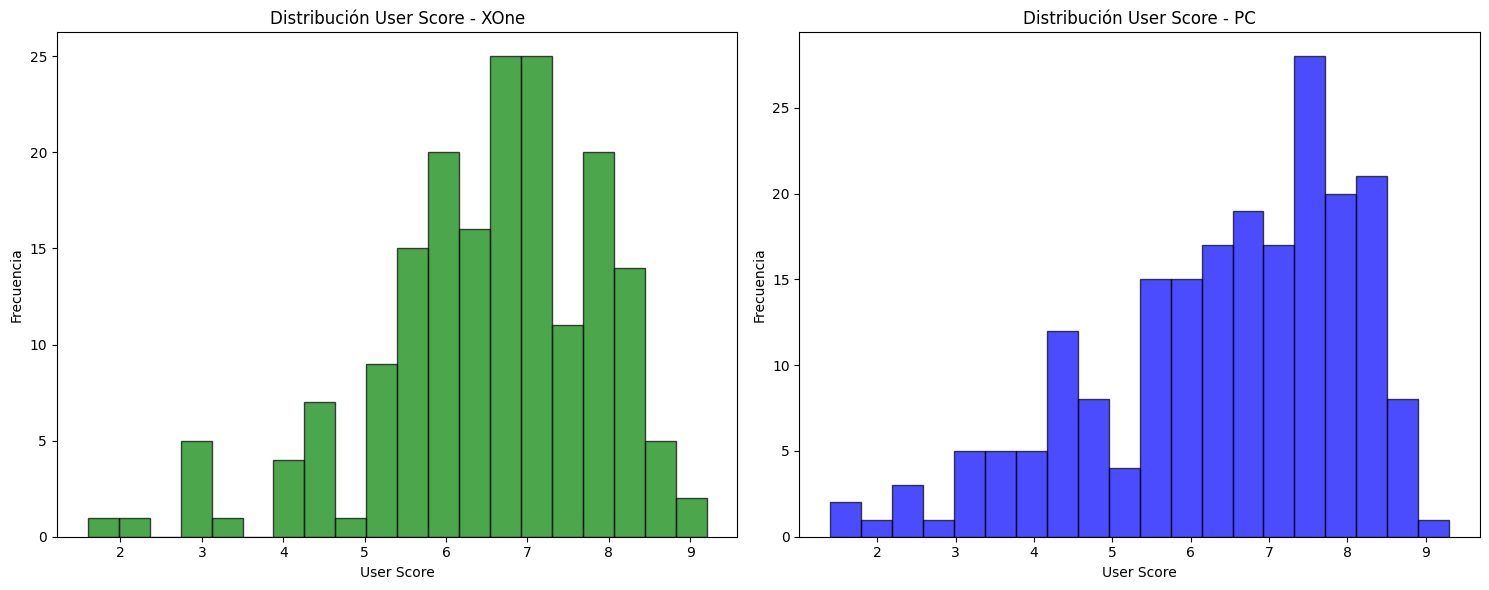

=== RESULTADOS DE LA PRUEBA T ===
Estadístico t: 0.5355 Valor p: 0.592612
Nivel de significancia (α): 0.05

🟢 NO RECHAZAMOS H₀
No hay evidencia suficiente de diferencia significativa

Diferencia de medias: 0.0828
=== CONCLUSIÓN ===
Con α = 0.05 y p-value = 0.592612:
Diferencia observada: XOne (6.521) vs PC (6.439)


In [26]:
#Calificación media usuarios XOne y PC iguales

# Filtrar datos para las plataformas de interés
xone_games = df_games_final[df_games_final['platform'] == 'XOne']['user score'].dropna()
pc_games = df_games_final[df_games_final['platform'] == 'PC']['user score'].dropna()

print("=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(f"Juegos con calificaciones de usuarios disponibles: XOne: {len(xone_games)} PC: {len(pc_games)}")
print(f"Calificación promedio usuarios: XOne: {xone_games.mean():.3f} PC: {pc_games.mean():.3f}")
print(f"Desviación estándar: XOne: {xone_games.std():.3f} PC: {pc_games.std():.3f}")

# Crear histogramas para comparar distribuciones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.hist(xone_games, bins=20, alpha=0.7, color='green', edgecolor='black')
ax1.set_title('Distribución User Score - XOne')
ax1.set_xlabel('User Score')
ax1.set_ylabel('Frecuencia')

ax2.hist(pc_games, bins=20, alpha=0.7, color='blue', edgecolor='black')
ax2.set_title('Distribución User Score - PC')
ax2.set_xlabel('User Score')
ax2.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

from scipy.stats import ttest_ind

# Realizar prueba t de dos muestras independientes
# (asumiendo varianzas desiguales - más conservador)
t_statistic, p_value = ttest_ind(xone_games, pc_games, equal_var=False)

print("=== RESULTADOS DE LA PRUEBA T ===")
print(f"Estadístico t: {t_statistic:.4f} Valor p: {p_value:.6f}")
print(f"Nivel de significancia (α): 0.05")
print()

# Interpretación de resultados
if p_value < 0.05:
    print("🔴 RECHAZAMOS H₀")
    print("Las calificaciones promedio son SIGNIFICATIVAMENTE DIFERENTES")
else:
    print("🟢 NO RECHAZAMOS H₀") 
    print("No hay evidencia suficiente de diferencia significativa")
    
print(f"\nDiferencia de medias: {xone_games.mean() - pc_games.mean():.4f}")

print("=== CONCLUSIÓN ===")
print(f"Con α = 0.05 y p-value = {p_value:.6f}:")
print(f"Diferencia observada: XOne ({xone_games.mean():.3f}) vs PC ({pc_games.mean():.3f})")


#### Observaciones:
1. Se realiza una prueba de hipótesis para evaluar la diferencia de las calificaciones de usuario para las plataformas XOne y PC.
2. Teniendo en cuenta que se cuenta con mas de 180 calificaciones para ambas plataformas, y revisando que las calificaciones siguen una distribución normal, con lígero sesgo a la derecha, se propone realizar una prueba estadística tipo t con una significancia de 5%.
3. El resultado de la prueba es que no se puede rechazar la hipótesis de que las calificaciones sean significativamente diferentes. De hecho, los datos iniciales mostraban una media muy parecida de 6.5 - 6.4 para ambas plataformas.


### Hipótesis 2: Las calificaciones promedio de los usuarios para los géneros de acción y deportes son diferentes.

H0: No hay diferencia apreciable en las calificaciones promedio de los usuarios en los géneros de acción y deportes

H1: Hay diferencia significativa para las calificaciones promedio de los usuarios en ambos géneros.

Alpha: 0.05

En este caso, teniendo en cuenta que ambos géneros tienen buena acogida en las ventas, quiero manejar una incertidumbre del 5%

=== ESTADÍSTICAS DESCRIPTIVAS ===
Juegos con calificaciones de usuarios disponibles: Action: 524 Sports: 195
Calificación promedio usuarios: Action: 6.828 Sports: 5.456
Desviación estándar: Action: 1.375 Sports: 1.739


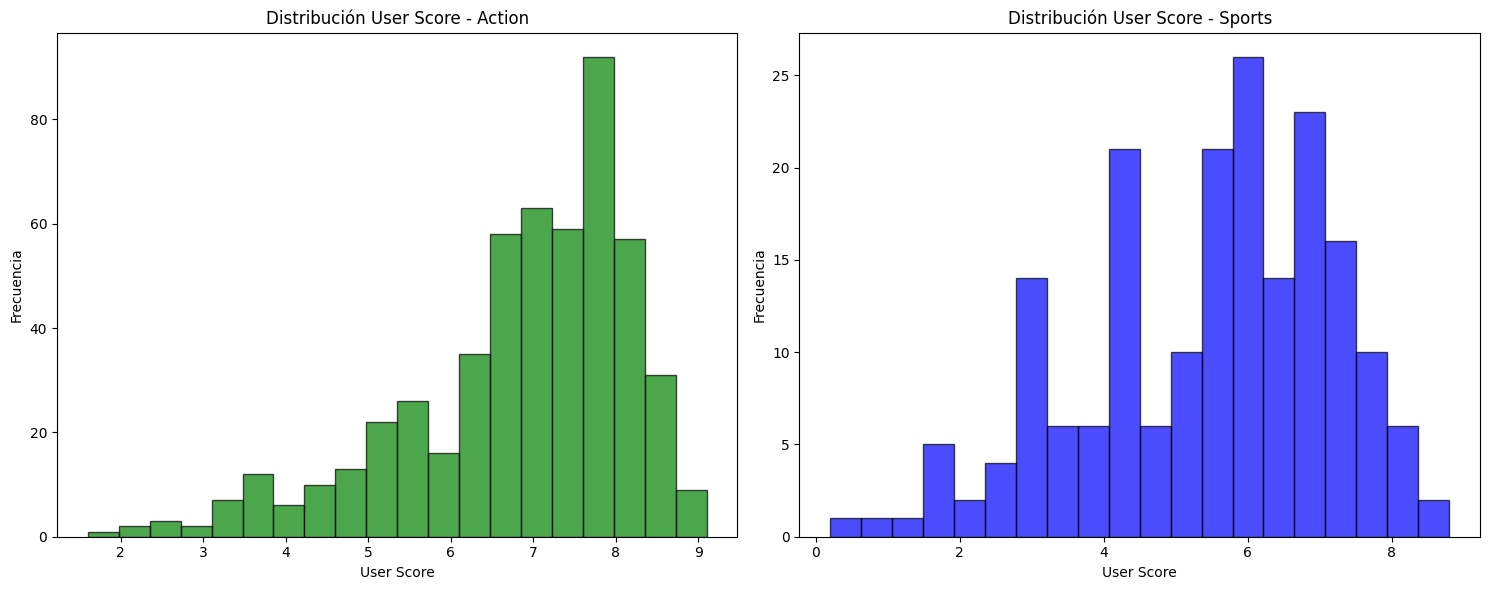

=== RESULTADOS DE LA PRUEBA T ===
Estadístico t: 9.9272 Valor p: 0.000000
Nivel de significancia (α): 0.05

🔴 RECHAZAMOS H₀
Las calificaciones promedio son SIGNIFICATIVAMENTE DIFERENTES

Diferencia de medias: 1.3723
=== CONCLUSIÓN ===
Con α = 0.05 y p-value = 0.000000:
Diferencia observada: Action (6.828) vs Sports (5.456)


In [27]:
#Calificación media usuarios action y sports iguales

# Filtrar datos para los géneros de interés
action_games = df_games_final[df_games_final['genre'] == 'Action']['user score'].dropna()
sports_games = df_games_final[df_games_final['genre'] == 'Sports']['user score'].dropna()

print("=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(f"Juegos con calificaciones de usuarios disponibles: Action: {len(action_games)} Sports: {len(sports_games)}")
print(f"Calificación promedio usuarios: Action: {action_games.mean():.3f} Sports: {sports_games.mean():.3f}")
print(f"Desviación estándar: Action: {action_games.std():.3f} Sports: {sports_games.std():.3f}")

# Crear histogramas para comparar distribuciones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.hist(action_games, bins=20, alpha=0.7, color='green', edgecolor='black')
ax1.set_title('Distribución User Score - Action')
ax1.set_xlabel('User Score')
ax1.set_ylabel('Frecuencia')

ax2.hist(sports_games, bins=20, alpha=0.7, color='blue', edgecolor='black')
ax2.set_title('Distribución User Score - Sports')
ax2.set_xlabel('User Score')
ax2.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()


# Realizar prueba t de dos muestras independientes
# (asumiendo varianzas desiguales - más conservador)
t_statistic2, p_value2 = ttest_ind(action_games, sports_games, equal_var=False)

print("=== RESULTADOS DE LA PRUEBA T ===")
print(f"Estadístico t: {t_statistic2:.4f} Valor p: {p_value2:.6f}")
print(f"Nivel de significancia (α): 0.05")
print()

# Interpretación de resultados
if p_value2 < 0.05:
    print("🔴 RECHAZAMOS H₀")
    print("Las calificaciones promedio son SIGNIFICATIVAMENTE DIFERENTES")
else:
    print("🟢 NO RECHAZAMOS H₀") 
    print("No hay evidencia suficiente de diferencia significativa")
    
print(f"\nDiferencia de medias: {action_games.mean() - sports_games.mean():.4f}")

print("=== CONCLUSIÓN ===")
print(f"Con α = 0.05 y p-value = {p_value2:.6f}:")
print(f"Diferencia observada: Action ({action_games.mean():.3f}) vs Sports ({sports_games.mean():.3f})")

#### Observaciones:
1. Se realiza una prueba de hipótesis para evaluar la diferencia de las calificaciones de usuario para los géneros de accióny deportes.
2. Para el género de deportes se tienen mas de 190 calificaciones de usuarios, y para el de acción se cuenta con mas de 500 calificaciones. Se tiene una diferencia apreciable pero son datos suficientes para montar una prueba de hipótesis. Ambas evaluaciones siguen una tendencia de distribución normal con lígero sesgo a la derecha. Por todo lo anterior se realiza una prueba estadística tipo t con una significancia de 5%.
3. Al contrario de lo ocurrido en la prueba anterior, si se observa una diferencia significativa en las calificaciones de los usuarios para los géneros de acción y de deportes. De hecho, viendo los histogramas de estas calificaciones, se pueden un aumento en las calificaciones entre 3 y 4 que ocasionan que las valoraciones medias cambien significativamente.

## Conclusiones generales:
1. Se ha realizado un análisis a los archivos de ventas de la empresa de videojuegos Ice, concentrando la atención al periodo 2012-2016, con el objetivo de suministrar información valiosa al departamento de mercadeo para establecer su campaña para 2017. El juego de datos disponible fue refinado para darle un mayor alcance al análisis y poder tener datos robustos que justifiquen las decisiones a tomar.
2. Se ha notado una reducción del lanzamiento de juegos desde 2009, año en el que se fue alcanzando el pico de lanzamientos. Se debe tener en cuenta que con la disponibilidad de juegos en línea y la aparición de teléfonos móviles, esto puede afectar la disponibilidad de un amplio catalogo de juegos.
3. En general, las plataformas tienen una vida útil de 10 años. Luego de aproximadamente 5 años las ventas de estas plataformas empiezan a decaer hasta su práctica desaparición. A esto se le debe sumar que las casas de plataformas sacan nuevas plataformas en aproximadamente 5 años, lo que ocasiona este declive en las ventas.
4. Las plataformas PC, PS4 y XOne son las que para 2016 tienen un alto potencial de explotarse de cara a 2017. Otras plataformas atractivas como WiiU, PSV y 3DS pueden tener potencial, pero estas plataformas considero que tienen mercados pequeños y no van a generar un alto impacto en las ventas totales.
5. Para el periodo 2012-2016 las plataformas X360 y PS3 eran líderes en ventas totales con un amplio catalogo de juegos, pero se debe tener en cuenta que a estas plataformas se han actualizado a PS4 y XOne, lo que ocasiona un declive en las ventas en los últimos años del estudio.
6. Se observa que la calificación que le dan los usuarios a los juegos no influye significativamente en las ventas. Por lo cual la campaña no debería tener en cuenta este apartado. Para la calificación de la crítica si se observa una relación lígera pero clara, pero su baja correlación debe tenerse en cuenta a la hora de formular la campaña a realizar.
7. La campaña se debe enfocar en juegos de Acción, deportes, shooter y juegos de rol. También se debería enfocar en juegos de Platform que presentan buena rentabilidad.
8. Hay que prestar atención a franquicias establecidas como Lego y FIFA, que para el periodo estudiado muestran ventas importantes y se encuentran disponibles para múltiples plataformas, ampliando el espectro de ventas.
9. Haciendo una segmentación del mercado por regiones, se encuentra que para Norteamérica y Europa la atención debe hacerse a las plataformas PS4 y XOne que vienen en auge, así como a la plataforma móvil 3DS. Para Japón debería enfocarse mas en plataformas móviles como 3DS y PSV así como en PS4. En Japón no hay buen mercado para las plataformas de Microsoft.
10. Para la misma segmentación regional, los juegos de acción, Shooter, deportes y de rol dominan el mercado para las regiones de Norteamérica y Europa. En Japón los juegos de acción son superados por los juegos de Rol. Se debe tener en cuenta que en japón los juegos de deportes y de shooter no tienen una buena penetración en ventas, esto puede ser definitivo a la hora de realizar campañas de mercadeo segmentadas por regiones.
11. Para la calificación ESRB, se observa que los juegos calificados E, E10+, T, M y No rated se encuentran en el top de las 3 regiones analizadas. En Japón se observa una mayor afinadad para las calificaciones E y T. El sesgo cultural se debe tener en cuenta a la hora de montar la campaña de mercadeo en las regiones.
12. Se Evalua si las calificaciones de usuarios para las plataformas de XOne y PC son distintas. El resultado de la prueba t realizada a los datos obtenidos muestra con una significancia mayor al 5% que no se puede rechazar la hipótesis.
13. Finalmente, se evalúa el efecto de las calificaciones de los usuarios para los géneros de acción y deportes. Con una incertidumbre del 5% se puede concluir que las calificaciones medias de estos géneros realizadas por los usuarios son diferentes. Esto también se corrobora mediante el comportamiento de histogramas.

Se entrega este análisis que brinda buena información al departamento de mercadeo de la empresa de videojuegos ICE para establecer su campaña de mercadeo para 2017.